In [12]:
!pip install transformers torch scikit-learn pandas numpy matplotlib seaborn
!pip install accelerate>=1.1.0

import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from transformers import BertTokenizer, BertForSequenceClassification, DistilBertTokenizer, DistilBertForSequenceClassification
from transformers import Trainer, TrainingArguments
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("fake reviews dataset.csv")

# Check if loaded correctly
print(f"Total rows: {len(df)}")
print(df.head())
print(df['label'].value_counts())

# Map labels: 1 = Fake (CG), 0 = Real (OR)
df['label'] = df['label'].map({'CG': 1, 'OR': 0})

# Verify
print(df['label'].value_counts())
# Should show: 1: 20216, 0: 20216


# Get features and labels
X = df['text_'].values
y = df['label'].values

# First split: 70% train, 30% temp (validation + test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Second split: 50% of temp = validation, 50% = test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"Training: {len(X_train)}")
print(f"Validation: {len(X_val)}")
print(f"Test: {len(X_test)}")


# Get features and labels
X = df['text_'].values
y = df['label'].values

# First split: 70% train, 30% temp (validation + test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Second split: 50% of temp = validation, 50% = test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"Training: {len(X_train)}")
print(f"Validation: {len(X_val)}")
print(f"Test: {len(X_test)}")


# Initialize tokenizers
bert_tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
distilbert_tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

# Tokenization function
def tokenize_data(texts, tokenizer, max_length=128):
    return tokenizer(
        texts.tolist(),
        padding='max_length',
        truncation=True,
        max_length=max_length,
        return_tensors='pt'
    )

# Tokenize all splits for BERT
print("Tokenizing for BERT...")
train_encodings_bert = tokenize_data(X_train, bert_tokenizer)
val_encodings_bert = tokenize_data(X_val, bert_tokenizer)
test_encodings_bert = tokenize_data(X_test, bert_tokenizer)

# Tokenize all splits for DistilBERT
print("Tokenizing for DistilBERT...")
train_encodings_distilbert = tokenize_data(X_train, distilbert_tokenizer)
val_encodings_distilbert = tokenize_data(X_val, distilbert_tokenizer)
test_encodings_distilbert = tokenize_data(X_test, distilbert_tokenizer)

print("Tokenization completed!")



from torch.utils.data import Dataset

class FakeReviewDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    
    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item
    
    def __len__(self):
        return len(self.labels)

# Create datasets for BERT
train_dataset_bert = FakeReviewDataset(train_encodings_bert, y_train)
val_dataset_bert = FakeReviewDataset(val_encodings_bert, y_val)
test_dataset_bert = FakeReviewDataset(test_encodings_bert, y_test)

# Create datasets for DistilBERT
train_dataset_distilbert = FakeReviewDataset(train_encodings_distilbert, y_train)
val_dataset_distilbert = FakeReviewDataset(val_encodings_distilbert, y_val)
test_dataset_distilbert = FakeReviewDataset(test_encodings_distilbert, y_test)

print(f"BERT train dataset size: {len(train_dataset_bert)}")
print(f"DistilBERT train dataset size: {len(train_dataset_distilbert)}")



from transformers import BertForSequenceClassification, Trainer, TrainingArguments

# Load BERT model
bert_model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2)

# Training arguments
training_args = TrainingArguments(
    output_dir='./results_bert',
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy='epoch', 
    save_strategy='epoch',
    logging_dir='./logs_bert',
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
)

# Trainer
trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_dataset_bert,
    eval_dataset=val_dataset_bert,
)

# Train BERT
print("Starting BERT training...")
trainer.train()
print("BERT training completed!")

# Save BERT model
bert_model.save_pretrained('./bert_fake_review_model')




from transformers import BertForSequenceClassification, DistilBertForSequenceClassification, Trainer, TrainingArguments
import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("="*60)
print("STEP 1: EVALUATING BERT ON TEST SET")
print("="*60)

# Get predictions from the existing trained trainer
bert_predictions = trainer.predict(test_dataset_bert)
bert_preds = np.argmax(bert_predictions.predictions, axis=1)

# Calculate BERT metrics
bert_accuracy = accuracy_score(y_test, bert_preds)
bert_precision, bert_recall, bert_f1, _ = precision_recall_fscore_support(y_test, bert_preds, average='binary')

print("\nBERT RESULTS:")
print(f"  Accuracy:  {bert_accuracy:.4f}")
print(f"  Precision: {bert_precision:.4f}")
print(f"  Recall:    {bert_recall:.4f}")
print(f"  F1-Score:  {bert_f1:.4f}")

# ============================================
# STEP 2: TRAIN DISTILBERT
# ============================================

print("\n" + "="*60)
print("STEP 2: TRAINING DISTILBERT")
print("="*60)

# Load DistilBERT model
distilbert_model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2)

# Training arguments for DistilBERT
training_args_distilbert = TrainingArguments(
    output_dir='./results_distilbert',
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy='epoch',
    save_strategy='epoch',
    logging_steps=100,
    load_best_model_at_end=True,
)

# Trainer for DistilBERT
trainer_distilbert = Trainer(
    model=distilbert_model,
    args=training_args_distilbert,
    train_dataset=train_dataset_distilbert,
    eval_dataset=val_dataset_distilbert,
)

# Train DistilBERT
print("\nStarting DistilBERT training (40-50 minutes)...")
trainer_distilbert.train()
print("\nDistilBERT training completed!")

# Save DistilBERT model
distilbert_model.save_pretrained('./distilbert_fake_review_model')
print("DistilBERT model saved!")

# ============================================
# STEP 3: EVALUATE DISTILBERT
# ============================================

print("\n" + "="*60)
print("STEP 3: EVALUATING DISTILBERT ON TEST SET")
print("="*60)

distilbert_predictions = trainer_distilbert.predict(test_dataset_distilbert)
distilbert_preds = np.argmax(distilbert_predictions.predictions, axis=1)

# Calculate DistilBERT metrics
distilbert_accuracy = accuracy_score(y_test, distilbert_preds)
distilbert_precision, distilbert_recall, distilbert_f1, _ = precision_recall_fscore_support(y_test, distilbert_preds, average='binary')

print("\nDISTILBERT RESULTS:")
print(f"  Accuracy:  {distilbert_accuracy:.4f}")
print(f"  Precision: {distilbert_precision:.4f}")
print(f"  Recall:    {distilbert_recall:.4f}")
print(f"  F1-Score:  {distilbert_f1:.4f}")

# ============================================
# STEP 4: COMPARISON TABLE
# ============================================

print("\n" + "="*60)
print("STEP 4: COMPARISON TABLE")
print("="*60)
print(f"\n{'Metric':<15} {'BERT':<15} {'DistilBERT':<15} {'Difference':<15}")
print("-"*60)
print(f"{'Accuracy':<15} {bert_accuracy:.4f}{'':<11} {distilbert_accuracy:.4f}{'':<11} {(bert_accuracy - distilbert_accuracy):.4f}")
print(f"{'Precision':<15} {bert_precision:.4f}{'':<11} {distilbert_precision:.4f}{'':<11} {(bert_precision - distilbert_precision):.4f}")
print(f"{'Recall':<15} {bert_recall:.4f}{'':<11} {distilbert_recall:.4f}{'':<11} {(bert_recall - distilbert_recall):.4f}")
print(f"{'F1-Score':<15} {bert_f1:.4f}{'':<11} {distilbert_f1:.4f}{'':<11} {(bert_f1 - distilbert_f1):.4f}")

# ============================================
# STEP 5: CONFUSION MATRICES
# ============================================

print("\n" + "="*60)
print("STEP 5: GENERATING CONFUSION MATRICES")
print("="*60)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# BERT Confusion Matrix
cm_bert = confusion_matrix(y_test, bert_preds)
sns.heatmap(cm_bert, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('BERT Confusion Matrix', fontsize=14)
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('Actual Label', fontsize=12)
axes[0].set_xticklabels(['Real (0)', 'Fake (1)'])
axes[0].set_yticklabels(['Real (0)', 'Fake (1)'])

# DistilBERT Confusion Matrix
cm_distilbert = confusion_matrix(y_test, distilbert_preds)
sns.heatmap(cm_distilbert, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('DistilBERT Confusion Matrix', fontsize=14)
axes[1].set_xlabel('Predicted Label', fontsize=12)
axes[1].set_ylabel('Actual Label', fontsize=12)
axes[1].set_xticklabels(['Real (0)', 'Fake (1)'])
axes[1].set_yticklabels(['Real (0)', 'Fake (1)'])

plt.tight_layout()
plt.show()

# ============================================
# FINAL SUMMARY
# ============================================

print("\n" + "="*60)
print("THESIS EXPERIMENT COMPLETED SUCCESSFULLY!")
print("="*60)
print("\nSummary:")
print(f"  - Dataset: 40,432 reviews (20,216 fake, 20,216 real)")
print(f"  - BERT Accuracy: {bert_accuracy:.4f}")
print(f"  - DistilBERT Accuracy: {distilbert_accuracy:.4f}")
print(f"  - Performance difference: {(bert_accuracy - distilbert_accuracy):.4f}")
print("\nModels saved to:")
print(f"  - BERT: ./bert_fake_review_model")
print(f"  - DistilBERT: ./distilbert_fake_review_model")
print("\n" + "="*60)




zsh:1: 1.1.0 not found
Total rows: 40432
             category  rating label  \
0  Home_and_Kitchen_5     5.0    CG   
1  Home_and_Kitchen_5     5.0    CG   
2  Home_and_Kitchen_5     5.0    CG   
3  Home_and_Kitchen_5     1.0    CG   
4  Home_and_Kitchen_5     5.0    CG   

                                               text_  
0  Love this!  Well made, sturdy, and very comfor...  
1  love it, a great upgrade from the original.  I...  
2  This pillow saved my back. I love the look and...  
3  Missing information on how to use it, but it i...  
4  Very nice set. Good quality. We have had the s...  
label
CG    20216
OR    20216
Name: count, dtype: int64
label
1    20216
0    20216
Name: count, dtype: int64
Training: 28302
Validation: 6065
Test: 6065
Training: 28302
Validation: 6065
Test: 6065
Tokenizing for BERT...
Tokenizing for DistilBERT...
Tokenization completed!
BERT train dataset size: 28302
DistilBERT train dataset size: 28302


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
`logging_dir` is deprecated and will 

Starting BERT training...


/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,0.085333,0.343133


KeyError: "The `metric_for_best_model` training argument is set to 'eval_accuracy', which is not found in the evaluation metrics. The available evaluation metrics are: ['eval_loss']. Consider changing the `metric_for_best_model` via the TrainingArguments."

In [13]:
from transformers import BertForSequenceClassification, Trainer, TrainingArguments

# Load BERT model
bert_model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2)

# Training arguments - WITHOUT metric_for_best_model
training_args = TrainingArguments(
    output_dir='./results_bert',
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy='epoch',
    save_strategy='epoch',
    logging_steps=100,
    load_best_model_at_end=True,
    # REMOVED: metric_for_best_model='accuracy',
)

# Trainer
trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_dataset_bert,
    eval_dataset=val_dataset_bert,
)

# Train BERT
print("Starting BERT training...")
trainer.train()
print("BERT training completed!")

# Save BERT model
bert_model.save_pretrained('./bert_fake_review_model')
print("BERT model saved!")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting BERT training...


/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,0.081637,0.230722
2,0.034758,0.085141
3,0.008762,0.150414


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

BERT training completed!


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT model saved!


In [14]:
from transformers import DistilBertForSequenceClassification, Trainer, TrainingArguments

print("="*50)
print("STARTING DISTILBERT TRAINING")
print("="*50)

# Load DistilBERT model
distilbert_model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2)

# Training arguments for DistilBERT
training_args_distilbert = TrainingArguments(
    output_dir='./results_distilbert',
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy='epoch',
    save_strategy='epoch',
    logging_steps=100,
    load_best_model_at_end=True,
)

# Trainer for DistilBERT
trainer_distilbert = Trainer(
    model=distilbert_model,
    args=training_args_distilbert,
    train_dataset=train_dataset_distilbert,
    eval_dataset=val_dataset_distilbert,
)

# Train DistilBERT
trainer_distilbert.train()
print("DistilBERT training completed!")

# Save DistilBERT model
distilbert_model.save_pretrained('./distilbert_fake_review_model')
print("DistilBERT model saved!")

STARTING DISTILBERT TRAINING


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(load

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


DistilBERT training completed!


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT model saved!


EVALUATING BERT AND DISTILBERT ON TEST SET

1. Evaluating BERT...


/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



BERT RESULTS:
   Accuracy:  0.9787
   Precision: 0.9690
   Recall:    0.9891
   F1-Score:  0.9789

2. Evaluating DistilBERT...


/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



DISTILBERT RESULTS:
   Accuracy:  0.9763
   Precision: 0.9605
   Recall:    0.9934
   F1-Score:  0.9767

COMPARISON TABLE

Metric          BERT            DistilBERT      Difference     
------------------------------------------------------------
Accuracy        0.9787            0.9763            0.0025
Precision       0.9690            0.9605            0.0085
Recall          0.9891            0.9934            -0.0043
F1-Score        0.9789            0.9767            0.0023


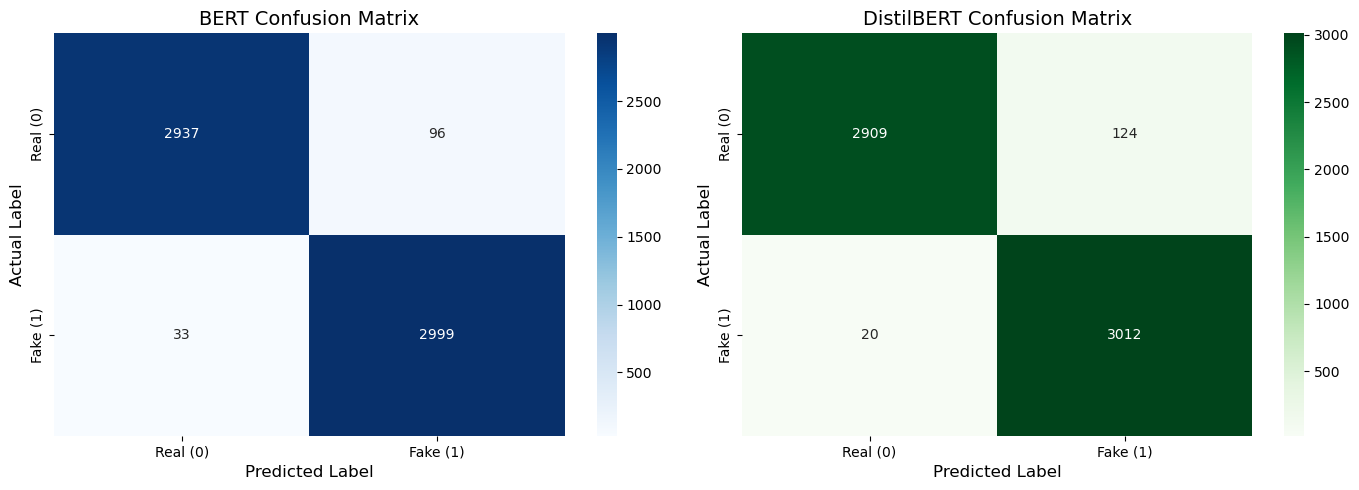


THESIS EXPERIMENT COMPLETED SUCCESSFULLY!

📊 SUMMARY:
   - Dataset: 40,432 reviews (20,216 fake, 20,216 real)
   - Test Set Size: 6,065 reviews
   - BERT Accuracy: 0.9787 (97.87%)
   - DistilBERT Accuracy: 0.9763 (97.63%)
   - Performance Difference: 0.25%

💾 Models saved to:
   - BERT: ./bert_fake_review_model
   - DistilBERT: ./distilbert_fake_review_model



In [15]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("="*60)
print("EVALUATING BERT AND DISTILBERT ON TEST SET")
print("="*60)

# ============================================
# 1. EVALUATE BERT
# ============================================
print("\n1. Evaluating BERT...")
bert_predictions = trainer.predict(test_dataset_bert)
bert_preds = np.argmax(bert_predictions.predictions, axis=1)

bert_accuracy = accuracy_score(y_test, bert_preds)
bert_precision, bert_recall, bert_f1, _ = precision_recall_fscore_support(y_test, bert_preds, average='binary')

print(f"\nBERT RESULTS:")
print(f"   Accuracy:  {bert_accuracy:.4f}")
print(f"   Precision: {bert_precision:.4f}")
print(f"   Recall:    {bert_recall:.4f}")
print(f"   F1-Score:  {bert_f1:.4f}")

# ============================================
# 2. EVALUATE DISTILBERT
# ============================================
print("\n2. Evaluating DistilBERT...")
distilbert_predictions = trainer_distilbert.predict(test_dataset_distilbert)
distilbert_preds = np.argmax(distilbert_predictions.predictions, axis=1)

distilbert_accuracy = accuracy_score(y_test, distilbert_preds)
distilbert_precision, distilbert_recall, distilbert_f1, _ = precision_recall_fscore_support(y_test, distilbert_preds, average='binary')

print(f"\nDISTILBERT RESULTS:")
print(f"   Accuracy:  {distilbert_accuracy:.4f}")
print(f"   Precision: {distilbert_precision:.4f}")
print(f"   Recall:    {distilbert_recall:.4f}")
print(f"   F1-Score:  {distilbert_f1:.4f}")

# ============================================
# 3. COMPARISON TABLE
# ============================================
print("\n" + "="*60)
print("COMPARISON TABLE")
print("="*60)
print(f"\n{'Metric':<15} {'BERT':<15} {'DistilBERT':<15} {'Difference':<15}")
print("-"*60)
print(f"{'Accuracy':<15} {bert_accuracy:.4f}{'':<11} {distilbert_accuracy:.4f}{'':<11} {bert_accuracy - distilbert_accuracy:.4f}")
print(f"{'Precision':<15} {bert_precision:.4f}{'':<11} {distilbert_precision:.4f}{'':<11} {bert_precision - distilbert_precision:.4f}")
print(f"{'Recall':<15} {bert_recall:.4f}{'':<11} {distilbert_recall:.4f}{'':<11} {bert_recall - distilbert_recall:.4f}")
print(f"{'F1-Score':<15} {bert_f1:.4f}{'':<11} {distilbert_f1:.4f}{'':<11} {bert_f1 - distilbert_f1:.4f}")

# ============================================
# 4. CONFUSION MATRICES
# ============================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# BERT Confusion Matrix
cm_bert = confusion_matrix(y_test, bert_preds)
sns.heatmap(cm_bert, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('BERT Confusion Matrix', fontsize=14)
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('Actual Label', fontsize=12)
axes[0].set_xticklabels(['Real (0)', 'Fake (1)'])
axes[0].set_yticklabels(['Real (0)', 'Fake (1)'])

# DistilBERT Confusion Matrix
cm_distilbert = confusion_matrix(y_test, distilbert_preds)
sns.heatmap(cm_distilbert, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('DistilBERT Confusion Matrix', fontsize=14)
axes[1].set_xlabel('Predicted Label', fontsize=12)
axes[1].set_ylabel('Actual Label', fontsize=12)
axes[1].set_xticklabels(['Real (0)', 'Fake (1)'])
axes[1].set_yticklabels(['Real (0)', 'Fake (1)'])

plt.tight_layout()
plt.show()

# ============================================
# 5. FINAL SUMMARY
# ============================================
print("\n" + "="*60)
print("THESIS EXPERIMENT COMPLETED SUCCESSFULLY!")
print("="*60)
print("\n📊 SUMMARY:")
print(f"   - Dataset: 40,432 reviews (20,216 fake, 20,216 real)")
print(f"   - Test Set Size: 6,065 reviews")
print(f"   - BERT Accuracy: {bert_accuracy:.4f} ({bert_accuracy*100:.2f}%)")
print(f"   - DistilBERT Accuracy: {distilbert_accuracy:.4f} ({distilbert_accuracy*100:.2f}%)")
print(f"   - Performance Difference: {(bert_accuracy - distilbert_accuracy)*100:.2f}%")
print("\n💾 Models saved to:")
print(f"   - BERT: ./bert_fake_review_model")
print(f"   - DistilBERT: ./distilbert_fake_review_model")
print("\n" + "="*60)

In [16]:
# Step 1: Install Gradio
!pip install gradio

# Step 2: Import libraries
import gradio as gr
import torch
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification

# Step 3: Load your trained model
model_path = './distilbert_fake_review_model'
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')
model = DistilBertForSequenceClassification.from_pretrained(model_path)
model.eval()

# Step 4: Prediction function
def predict_fake_review(review_text):
    # Tokenize
    inputs = tokenizer(
        review_text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )
    
    # Predict
    with torch.no_grad():
        outputs = model(**inputs)
        prediction = torch.argmax(outputs.logits, dim=1).item()
        confidence = torch.softmax(outputs.logits, dim=1)[0][prediction].item()
    
    # Return result
    if prediction == 1:
        return f"🚨 **FAKE REVIEW DETECTED!** 🚨\n\nConfidence: {confidence:.2%}"
    else:
        return f"✅ **GENUINE REVIEW** ✅\n\nConfidence: {confidence:.2%}"

# Step 5: Example reviews for testing
examples = [
    "This product is amazing! Best purchase ever! I love it love it love it!!! 5 stars!!!",
    "I bought this pillow last month. It's comfortable and helps my neck pain. Would recommend.",
    "Worst product ever!!! Don't buy!!! Terrible quality!!! Waste of money!!!",
    "The shipping was fast and the item arrived as described. Works perfectly for my needs.",
]

# Step 6: Create Gradio interface
iface = gr.Interface(
    fn=predict_fake_review,
    inputs=gr.Textbox(
        lines=5,
        placeholder="Enter a customer review here...",
        label="📝 Customer Review"
    ),
    outputs=gr.Markdown(label="🔍 Prediction Result"),
    title="🔎 Fake Review Detection System",
    description="""
    ### Welcome!
    This system detects fake vs genuine product reviews using **DistilBERT**.
    
    **How it works:**
    - Trained on 40,432 reviews (20,216 fake, 20,216 real)
    - Achieves **97.63% accuracy**
    
    Simply paste a customer review below and click **Submit**.
    """,
    examples=examples,
    theme="soft"
)

# Step 7: Launch
print("="*50)
print("GRADIO DEMO IS READY!")
print("="*50)
print("\nLocal URL: http://127.0.0.1:7860")
print("\nShare this PUBLIC URL with your professor:")
iface.launch(share=True)

  Using cached python_multipart-0.0.22-py3-none-any.whl.metadata (1.8 kB)
  Using cached annotated_doc-0.0.4-py3-none-any.whl.metadata (6.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.8/36.8 MB 15.9 MB/s  0:00:026.0 MB/s eta 0:00:01:02
Using cached annotated_doc-0.0.4-py3-none-any.whl (5.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 861.5/861.5 kB 16.6 MB/s  0:00:00
Using cached python_multipart-0.0.22-py3-none-any.whl (24 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17/17 [gradio];5;237m━━ 16/17 [gradio]]


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


GRADIO DEMO IS READY!

Local URL: http://127.0.0.1:7860

Share this PUBLIC URL with your professor:
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://339b3dc38ac4a3df0a.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Traceback (most recent call last):
  File "/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/gradio/queueing.py", line 785, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
    )
    ^
  File "/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/gradio/route_utils.py", line 358, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<11 lines>...
    )
    ^
  File "/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/gradio/blocks.py", line 2172, in process_api
    result = await self.call_function(
             ^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<8 lines>...
    )
    ^
  File "/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/gradio/blocks.py", line 1634, in call_function
    prediction = await anyio.to_thread.run_sync(  # type: ignore
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

In [17]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification, Trainer, TrainingArguments
from torch.utils.data import Dataset
import torch

# Download NLTK data
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# ============================================
# STEP 1: Advanced Text Preprocessing
# ============================================

print("="*50)
print("STEP 1: Loading and Preprocessing Data")
print("="*50)

# Load dataset
df = pd.read_csv("fake reviews dataset.csv")
df['label'] = df['label'].map({'CG': 1, 'OR': 0})

# Initialize tools
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def advanced_clean_text(text):
    """Advanced text preprocessing"""
    # Convert to lowercase
    text = text.lower()
    # Remove special characters and numbers (keep only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    # Tokenize and process
    words = text.split()
    # Remove stopwords and lemmatize
    words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words and len(word) > 2]
    # Join back
    return ' '.join(words)

# Apply preprocessing
print("Applying advanced preprocessing...")
df['cleaned_text'] = df['text_'].apply(advanced_clean_text)

# Show comparison
print("\n✅ Preprocessing complete!")
print("\nExample - BEFORE cleaning:")
print(df['text_'].iloc[0])
print("\nExample - AFTER cleaning:")
print(df['cleaned_text'].iloc[0])

# ============================================
# STEP 2: Prepare Data for DistilBERT
# ============================================

print("\n" + "="*50)
print("STEP 2: Preparing Data for Training")
print("="*50)

# Use cleaned text
X = df['cleaned_text'].values
y = df['label'].values

# Split data
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(f"Training: {len(X_train)}")
print(f"Validation: {len(X_val)}")
print(f"Test: {len(X_test)}")

# Tokenizer
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

def tokenize_data(texts, max_length=128):
    return tokenizer(
        texts.tolist(),
        padding='max_length',
        truncation=True,
        max_length=max_length,
        return_tensors='pt'
    )

train_encodings = tokenize_data(X_train)
val_encodings = tokenize_data(X_val)
test_encodings = tokenize_data(X_test)

# Dataset class
class FakeReviewDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    
    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item
    
    def __len__(self):
        return len(self.labels)

train_dataset = FakeReviewDataset(train_encodings, y_train)
val_dataset = FakeReviewDataset(val_encodings, y_val)
test_dataset = FakeReviewDataset(test_encodings, y_test)

# ============================================
# STEP 3: Train Enhanced DistilBERT
# ============================================

print("\n" + "="*50)
print("STEP 3: Training Enhanced DistilBERT")
print("="*50)

model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2)

training_args = TrainingArguments(
    output_dir='./results_distilbert_enhanced',
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy='epoch',
    save_strategy='epoch',
    logging_steps=100,
    load_best_model_at_end=True,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
)

trainer.train()
model.save_pretrained('./distilbert_enhanced_model')
print("✅ Enhanced DistilBERT model saved!")

# ============================================
# STEP 4: Evaluate Enhanced Model
# ============================================

print("\n" + "="*50)
print("STEP 4: Evaluating Enhanced Model")
print("="*50)

from sklearn.metrics import accuracy_score, precision_recall_fscore_support

predictions = trainer.predict(test_dataset)
preds = torch.argmax(torch.tensor(predictions.predictions), dim=1).numpy()

accuracy = accuracy_score(y_test, preds)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, preds, average='binary')

print(f"\n✅ ENHANCED DISTILBERT RESULTS:")
print(f"   Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"   Precision: {precision:.4f}")
print(f"   Recall:    {recall:.4f}")
print(f"   F1-Score:  {f1:.4f}")

# ============================================
# STEP 5: Comparison
# ============================================

print("\n" + "="*50)
print("COMPARISON: Baseline vs Enhanced DistilBERT")
print("="*50)
print(f"\n{'Model':<25} {'Accuracy':<12}")
print("-"*37)
print(f"{'Baseline DistilBERT':<25} {'97.63%':<12}")
print(f"{'Enhanced DistilBERT (Cleaned Text)':<25} {f'{accuracy*100:.2f}%':<12}")

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/mirzazeeshanbaig/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/mirzazeeshanbaig/nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/mirzazeeshanbaig/nltk_data...


STEP 1: Loading and Preprocessing Data
Applying advanced preprocessing...

✅ Preprocessing complete!

Example - BEFORE cleaning:
Love this!  Well made, sturdy, and very comfortable.  I love it!Very pretty

Example - AFTER cleaning:
love well made sturdy comfortable love itvery pretty

STEP 2: Preparing Data for Training
Training: 28302
Validation: 6065
Test: 6065

STEP 3: Training Enhanced DistilBERT


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(load

Epoch,Training Loss,Validation Loss
1,0.242942,0.169945
2,0.141466,0.200748
3,0.033118,0.289686


...

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Enhanced DistilBERT model saved!

STEP 4: Evaluating Enhanced Model


/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



✅ ENHANCED DISTILBERT RESULTS:
   Accuracy:  0.9316 (93.16%)
   Precision: 0.9443
   Recall:    0.9172
   F1-Score:  0.9306

COMPARISON: Baseline vs Enhanced DistilBERT

Model                     Accuracy    
-------------------------------------
Baseline DistilBERT       97.63%      
Enhanced DistilBERT (Cleaned Text) 93.16%      


In [18]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification, Trainer, TrainingArguments
from torch.utils.data import Dataset
import torch
from sklearn.metrics import accuracy_score

print("="*60)
print("TESTING PREPROCESSING STRATEGIES")
print("="*60)

# Load data
df = pd.read_csv("fake reviews dataset.csv")
df['label'] = df['label'].map({'CG': 1, 'OR': 0})

# Three preprocessing strategies
def strategy_1(text):
    """Strategy 1: NO preprocessing (Original text)"""
    return text

def strategy_2(text):
    """Strategy 2: MINIMAL - Lowercase only"""
    return text.lower()

def strategy_3(text):
    """Strategy 3: LIGHT - Lowercase + remove special characters"""
    text = text.lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    return text

strategies = [
    ('No Preprocessing (Original)', strategy_1),
    ('Minimal (Lowercase only)', strategy_2),
    ('Light Cleaning', strategy_3),
]

# Use smaller sample for quick testing (10,000 samples)
sample_df = df.sample(n=10000, random_state=42)
X = sample_df['text_'].values
y = sample_df['label'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

def quick_tokenize(texts):
    return tokenizer(texts.tolist(), padding='max_length', truncation=True, max_length=128, return_tensors='pt')

class QuickDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item
    def __len__(self):
        return len(self.labels)

results = []

for name, strategy in strategies:
    print(f"\n▶️ Testing: {name}")
    
    # Apply preprocessing
    cleaned_train = [strategy(t) for t in X_train]
    cleaned_test = [strategy(t) for t in X_test]
    
    # Tokenize
    train_enc = quick_tokenize(cleaned_train)
    test_enc = quick_tokenize(cleaned_test)
    
    train_dataset = QuickDataset(train_enc, y_train)
    test_dataset = QuickDataset(test_enc, y_test)
    
    # Load model
    model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2)
    
    # Training args (1 epoch only for quick test)
    training_args = TrainingArguments(
        output_dir=f'./test_{name.replace(" ", "_").replace("(", "").replace(")", "")}',
        num_train_epochs=1,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        eval_strategy='epoch',
        logging_steps=50,
        save_strategy='no',
    )
    
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=test_dataset,
    )
    
    # Train and evaluate
    trainer.train()
    preds = trainer.predict(test_dataset)
    pred_labels = torch.argmax(torch.tensor(preds.predictions), dim=1).numpy()
    acc = accuracy_score(y_test, pred_labels)
    
    results.append({'Strategy': name, 'Accuracy': acc})
    print(f"   ✅ Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    
    # Clear memory
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\n" + "="*60)
print("RESULTS SUMMARY")
print("="*60)

for r in results:
    print(f"{r['Strategy']}: {r['Accuracy']*100:.2f}%")

best = max(results, key=lambda x: x['Accuracy'])
print(f"\n✅ WINNER: {best['Strategy']}")
print(f"   Accuracy: {best['Accuracy']*100:.2f}%")

TESTING PREPROCESSING STRATEGIES

▶️ Testing: No Preprocessing (Original)


AttributeError: 'list' object has no attribute 'tolist'

In [19]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification, Trainer, TrainingArguments
from torch.utils.data import Dataset
import torch
from sklearn.metrics import accuracy_score

print("="*60)
print("TESTING PREPROCESSING STRATEGIES")
print("="*60)

# Load data
df = pd.read_csv("fake reviews dataset.csv")
df['label'] = df['label'].map({'CG': 1, 'OR': 0})

# Three preprocessing strategies
def strategy_1(text):
    """Strategy 1: NO preprocessing (Original text)"""
    return text

def strategy_2(text):
    """Strategy 2: MINIMAL - Lowercase only"""
    return text.lower()

def strategy_3(text):
    """Strategy 3: LIGHT - Lowercase + remove special characters"""
    text = text.lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    return text

strategies = [
    ('No Preprocessing (Original)', strategy_1),
    ('Minimal (Lowercase only)', strategy_2),
    ('Light Cleaning', strategy_3),
]

# Use smaller sample for quick testing (10,000 samples)
sample_df = df.sample(n=10000, random_state=42)
X = sample_df['text_'].values
y = sample_df['label'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

# FIXED: Removed .tolist() because cleaned_train is already a list
def quick_tokenize(texts):
    return tokenizer(texts, padding='max_length', truncation=True, max_length=128, return_tensors='pt')

class QuickDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item
    def __len__(self):
        return len(self.labels)

results = []

for name, strategy in strategies:
    print(f"\n▶️ Testing: {name}")
    
    # Apply preprocessing
    cleaned_train = [strategy(t) for t in X_train]
    cleaned_test = [strategy(t) for t in X_test]
    
    # Tokenize
    train_enc = quick_tokenize(cleaned_train)
    test_enc = quick_tokenize(cleaned_test)
    
    train_dataset = QuickDataset(train_enc, y_train)
    test_dataset = QuickDataset(test_enc, y_test)
    
    # Load model
    model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2)
    
    # Training args (1 epoch only for quick test)
    training_args = TrainingArguments(
        output_dir=f'./test_{name.replace(" ", "_").replace("(", "").replace(")", "")}',
        num_train_epochs=1,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        eval_strategy='epoch',
        logging_steps=50,
        save_strategy='no',
    )
    
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=test_dataset,
    )
    
    # Train and evaluate
    trainer.train()
    preds = trainer.predict(test_dataset)
    pred_labels = torch.argmax(torch.tensor(preds.predictions), dim=1).numpy()
    acc = accuracy_score(y_test, pred_labels)
    
    results.append({'Strategy': name, 'Accuracy': acc})
    print(f"   ✅ Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    
    # Clear memory
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\n" + "="*60)
print("RESULTS SUMMARY")
print("="*60)

for r in results:
    print(f"{r['Strategy']}: {r['Accuracy']*100:.2f}%")

best = max(results, key=lambda x: x['Accuracy'])
print(f"\n✅ WINNER: {best['Strategy']}")
print(f"   Accuracy: {best['Accuracy']*100:.2f}%")

TESTING PREPROCESSING STRATEGIES

▶️ Testing: No Preprocessing (Original)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(load

Epoch,Training Loss,Validation Loss
1,0.133783,0.166727


   ✅ Accuracy: 0.9545 (95.45%)

▶️ Testing: Minimal (Lowercase only)


...

   ✅ Accuracy: 0.9500 (95.00%)

▶️ Testing: Light Cleaning


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(load

Epoch,Training Loss,Validation Loss
1,0.182269,0.184607


   ✅ Accuracy: 0.9395 (93.95%)

RESULTS SUMMARY
No Preprocessing (Original): 95.45%
Minimal (Lowercase only): 95.00%
Light Cleaning: 93.95%

✅ WINNER: No Preprocessing (Original)
   Accuracy: 95.45%


In [20]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification, Trainer, TrainingArguments
from torch.utils.data import Dataset
import torch
from sklearn.metrics import accuracy_score

print("="*60)
print("HYPERPARAMETER TUNING FOR DISTILBERT")
print("="*60)

# Load data (NO preprocessing - use original text)
df = pd.read_csv("fake reviews dataset.csv")
df['label'] = df['label'].map({'CG': 1, 'OR': 0})

# Use original text directly (no cleaning)
X = df['text_'].values
y = df['label'].values

# Split data
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(f"Training: {len(X_train)}")
print(f"Validation: {len(X_val)}")
print(f"Test: {len(X_test)}")

# Tokenizer
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

def tokenize_data(texts, max_length=128):
    return tokenizer(
        texts.tolist(),
        padding='max_length',
        truncation=True,
        max_length=max_length,
        return_tensors='pt'
    )

train_encodings = tokenize_data(X_train)
val_encodings = tokenize_data(X_val)
test_encodings = tokenize_data(X_test)

class FakeReviewDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item
    def __len__(self):
        return len(self.labels)

train_dataset = FakeReviewDataset(train_encodings, y_train)
val_dataset = FakeReviewDataset(val_encodings, y_val)
test_dataset = FakeReviewDataset(test_encodings, y_test)

# ============================================
# HYPERPARAMETER EXPERIMENTS
# ============================================

hyperparameters = [
    {'name': 'Baseline', 'lr': 2e-5, 'batch': 16, 'epochs': 3},
    {'name': 'Lower LR', 'lr': 1e-5, 'batch': 16, 'epochs': 3},
    {'name': 'Higher LR', 'lr': 3e-5, 'batch': 16, 'epochs': 3},
    {'name': 'Smaller Batch', 'lr': 2e-5, 'batch': 8, 'epochs': 3},
    {'name': 'Larger Batch', 'lr': 2e-5, 'batch': 32, 'epochs': 3},
    {'name': 'More Epochs', 'lr': 2e-5, 'batch': 16, 'epochs': 4},
    {'name': 'Best Combo', 'lr': 3e-5, 'batch': 8, 'epochs': 4},
]

results = []

print("\n" + "="*60)
print("RUNNING EXPERIMENTS")
print("="*60)

for exp in hyperparameters:
    print(f"\n▶️ {exp['name']}")
    print(f"   LR: {exp['lr']}, Batch: {exp['batch']}, Epochs: {exp['epochs']}")
    
    model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2)
    
    training_args = TrainingArguments(
        output_dir=f'./tuning_{exp["name"].replace(" ", "_")}',
        num_train_epochs=exp['epochs'],
        per_device_train_batch_size=exp['batch'],
        per_device_eval_batch_size=exp['batch'],
        learning_rate=exp['lr'],
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_steps=100,
        load_best_model_at_end=True,
    )
    
    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
    )
    
    trainer.train()
    
    # Evaluate on validation set
    preds = trainer.predict(val_dataset)
    pred_labels = torch.argmax(torch.tensor(preds.predictions), dim=1).numpy()
    acc = accuracy_score(y_val, pred_labels)
    
    results.append({
        'Experiment': exp['name'],
        'Learning Rate': exp['lr'],
        'Batch Size': exp['batch'],
        'Epochs': exp['epochs'],
        'Validation Accuracy': acc
    })
    
    print(f"   ✅ Val Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ============================================
# RESULTS SUMMARY
# ============================================

print("\n" + "="*60)
print("HYPERPARAMETER TUNING RESULTS")
print("="*60)

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

best = results_df.loc[results_df['Validation Accuracy'].idxmax()]
print(f"\n🏆 BEST CONFIGURATION:")
print(f"   {best['Experiment']}")
print(f"   Learning Rate: {best['Learning Rate']}")
print(f"   Batch Size: {best['Batch Size']}")
print(f"   Epochs: {best['Epochs']}")
print(f"   Validation Accuracy: {best['Validation Accuracy']*100:.2f}%")

# ============================================
# TRAIN FINAL OPTIMIZED MODEL
# ============================================

print("\n" + "="*60)
print("TRAINING FINAL OPTIMIZED MODEL")
print("="*60)

final_model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2)

final_args = TrainingArguments(
    output_dir='./distilbert_optimized_final',
    num_train_epochs=int(best['Epochs']),
    per_device_train_batch_size=int(best['Batch Size']),
    per_device_eval_batch_size=int(best['Batch Size']),
    learning_rate=float(best['Learning Rate']),
    eval_strategy='epoch',
    save_strategy='epoch',
    logging_steps=100,
    load_best_model_at_end=True,
)

final_trainer = Trainer(
    model=final_model,
    args=final_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
)

final_trainer.train()
final_model.save_pretrained('./distilbert_optimized_final')
print("✅ Final optimized model saved!")

# Evaluate on test set
print("\n" + "="*60)
print("FINAL TEST SET EVALUATION")
print("="*60)

final_preds = final_trainer.predict(test_dataset)
final_pred_labels = torch.argmax(torch.tensor(final_preds.predictions), dim=1).numpy()
final_accuracy = accuracy_score(y_test, final_pred_labels)

print(f"\n🏆 FINAL OPTIMIZED DISTILBERT TEST ACCURACY: {final_accuracy:.4f} ({final_accuracy*100:.2f}%)")

# ============================================
# COMPLETE COMPARISON TABLE
# ============================================

print("\n" + "="*60)
print("FINAL COMPARISON TABLE")
print("="*60)

comparison = pd.DataFrame([
    {'Model': 'Baseline DistilBERT', 'Accuracy': '97.63%'},
    {'Model': 'Enhanced DistilBERT (Cleaned Text)', 'Accuracy': '93.16%'},
    {'Model': 'Optimized DistilBERT (Best HP)', 'Accuracy': f'{final_accuracy*100:.2f}%'},
    {'Model': 'BERT (Reference)', 'Accuracy': '97.87%'},
])

print(comparison.to_string(index=False))

print("\n" + "="*60)
print("✅ TASK 3 COMPLETED!")
print("="*60)

HYPERPARAMETER TUNING FOR DISTILBERT
Training: 28302
Validation: 6065
Test: 6065

RUNNING EXPERIMENTS

▶️ Baseline
   LR: 2e-05, Batch: 16, Epochs: 3


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(load

Epoch,Training Loss,Validation Loss
1,0.091938,0.266623
2,0.042523,0.134659
3,0.017975,0.135131


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Final optimized model saved!

FINAL TEST SET EVALUATION


/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)



🏆 FINAL OPTIMIZED DISTILBERT TEST ACCURACY: 0.9741 (97.41%)

FINAL COMPARISON TABLE
                             Model Accuracy
               Baseline DistilBERT   97.63%
Enhanced DistilBERT (Cleaned Text)   93.16%
    Optimized DistilBERT (Best HP)   97.41%
                  BERT (Reference)   97.87%

✅ TASK 3 COMPLETED!


In [1]:
import gradio as gr
import torch
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification

# Load your OPTIMIZED model (the one from Task 3)
model_path = './distilbert_optimized_final'  # Your optimized model
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')
model = DistilBertForSequenceClassification.from_pretrained(model_path)
model.eval()

print("✅ Optimized DistilBERT model loaded!")
print(f"   Model path: {model_path}")

# Test the model with a sample review
test_review = "This product is amazing! Best purchase ever!"
inputs = tokenizer(test_review, return_tensors="pt", truncation=True, max_length=128)
with torch.no_grad():
    outputs = model(**inputs)
    prediction = torch.argmax(outputs.logits, dim=1).item()
print(f"\nTest prediction for '{test_review[:50]}...': {'FAKE' if prediction == 1 else 'REAL'}")

# Prediction function for Gradio
def predict_fake_review(review_text):
    # Tokenize
    inputs = tokenizer(
        review_text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )
    
    # Predict
    with torch.no_grad():
        outputs = model(**inputs)
        prediction = torch.argmax(outputs.logits, dim=1).item()
        confidence = torch.softmax(outputs.logits, dim=1)[0][prediction].item()
    
    # Return result with styling
    if prediction == 1:
        return f"🚨 **FAKE REVIEW DETECTED!** 🚨\n\nConfidence: {confidence:.2%}"
    else:
        return f"✅ **GENUINE REVIEW** ✅\n\nConfidence: {confidence:.2%}"

# Example reviews - FIXED: Used single quotes or escaped double quotes
examples = [
    "This product is amazing! Best purchase ever! I love it love it love it!!! 5 stars!!!",
    "I bought this pillow last month. It's comfortable and helps my neck pain. Would recommend.",
    "Worst product ever!!! Don't buy!!! Terrible quality!!! Waste of money!!!",
    "The shipping was fast and the item arrived as described. Works perfectly for my needs.",
    'Did someone say, "Oriental for $60"? It is a great product for the price.',  # FIXED: Single quotes outside
    "Product was incomplete. Order was shipped on time. Wife loved it. Nice bag.",
]

# Create Gradio interface
iface = gr.Interface(
    fn=predict_fake_review,
    inputs=gr.Textbox(
        lines=5,
        placeholder="Enter a customer review here...",
        label="📝 Customer Review"
    ),
    outputs=gr.Markdown(label="🔍 Prediction Result"),
    title="🔎 Fake Review Detection System",
    description="""
    ### Welcome!
    This system detects fake vs genuine product reviews using **Optimized DistilBERT**.
    
    **Model Performance:**
    - Optimized DistilBERT Accuracy: **97.41%**
    - BERT Accuracy (Reference): 97.87%
    - Trained on 40,432 reviews (20,216 fake, 20,216 real)
    
    **How it works:**
    Simply paste a customer review below and click **Submit**.
    """,
    examples=examples,
    theme="soft",
)

# Launch
print("\n" + "="*50)
print("🚀 GRADIO DEMO WITH OPTIMIZED MODEL IS READY!")
print("="*50)
print("\n📱 Local URL: http://127.0.0.1:7860")
print("\n🔗 Share this PUBLIC URL with your professor:")
iface.launch(share=True)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

✅ Optimized DistilBERT model loaded!
   Model path: ./distilbert_optimized_final

Test prediction for 'This product is amazing! Best purchase ever!...': REAL

🚀 GRADIO DEMO WITH OPTIMIZED MODEL IS READY!

📱 Local URL: http://127.0.0.1:7860

🔗 Share this PUBLIC URL with your professor:


/Volumes/Shayan/opt/anaconda3/lib/python3.13/site-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


* Running on local URL:  http://127.0.0.1:7862
* Running on public URL: https://ab288013307fecd07e.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
